# 03 — Baseline, fine-tuning, calibration and threshold

**What this notebook does.** It trains two models and fixes the settings the test will use:

| Model | What it is | Why |
|---|---|---|
| **Baseline** | MobileNetV2 with ImageNet weights, *never trained*, turns each patch into 1,280 numbers; logistic regression learns from them | Shows what generic image features achieve with no adaptation, so the gain from fine-tuning can be measured |
| **Fine-tuned model** (main model) | MobileNetV2 with ImageNet weights plus a new final layer, trained in two stages on mammogram patches | Small and fast enough for ordinary hardware |

It then sets, on the validation set only:
- the **temperature** (calibration), so the probability shown matches how often the model is right, and
- the **threshold** (decision cut-off), chosen to catch at least 90% of malignant masses.

Both are saved in `locked.json` and are **not changed after this notebook**.

**Rule.** Only training and validation patches are used. The test set is not opened here, so the test results
in notebook 04 stay honest.

**Input** (Kaggle: *Add Input*): the output of notebook 02 (`patches/` and `patch_index.csv`).

**Output** (`/kaggle/working/model`)

| File | Contents |
|---|---|
| `model.keras` | The fine-tuned model |
| `baseline_logreg.joblib` | The baseline logistic regression |
| `locked.json` | Temperature, threshold, validation results and all settings |
| `val_predictions.csv` | Each validation patch's score and probability from both models |
| `training_curves.png` | Training and validation AUROC per epoch |
| `best.weights.h5` | Backup of the model weights |

**Settings.** Accelerator: GPU. Internet: On (downloads the ImageNet weights once).
Run with *Save Version → Save & Run All*.

## 0. Check the attached inputs
Lists what is attached under `/kaggle/input`. The patches from notebook 02 should appear (3,395 files:
1,696 patches, 1,696 outlines and three others).

In [1]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    print(root, "|", len(files), "files", "| e.g.", files[:3])

/kaggle/input | 0 files | e.g. []
/kaggle/input/notebooks | 0 files | e.g. []
/kaggle/input/notebooks/abdussalamhameedat | 0 files | e.g. []
/kaggle/input/notebooks/abdussalamhameedat/02-patch-notebook | 4 files | e.g. ['__notebook__.ipynb', '__output__.json', '__results__.html']
/kaggle/input/notebooks/abdussalamhameedat/02-patch-notebook/__results___files | 1 files | e.g. ['__results___9_0.png']
/kaggle/input/notebooks/abdussalamhameedat/02-patch-notebook/patches | 3395 files | e.g. ['Test_P_00016_LEFT_CC_1_img.png', 'Test_P_00016_LEFT_CC_1_mask.png', 'Test_P_00016_LEFT_MLO_1_img.png']


## 1. Setup and settings

| Setting | Value | Meaning |
|---|---|---|
| `img` | 224 | Patches are resized to 224×224 pixels, MobileNetV2's standard input |
| `batch` | 32 | Patches per training step |
| `epochs_head`, `epochs_ft` | 15, 30 | Maximum epochs for stage 1 and stage 2 |
| `patience` | 6 | Stop a stage if validation AUROC has not improved for 6 epochs |
| `lr_head`, `lr_ft` | 0.001, 0.00002 | Learning rates; much lower in stage 2 so the pretrained layers change gently |
| `unfreeze_from` | `block_13_expand` | In stage 2, layers from here upward are trained |
| `target_sensitivity` | 0.90 | The threshold must catch at least 90% of malignant validation masses |
| `seed` | 42 | Fixed random seed so the run can be repeated |

In [2]:
import os, json, random, time
from pathlib import Path
import numpy as np, pandas as pd, cv2, joblib
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
import tensorflow as tf, keras

SMOKE = os.environ.get("SMOKE") == "1"            # tiny test run only; ignore on Kaggle
CFG = dict(
    seed=42, img=224, batch=32,
    epochs_head=3 if SMOKE else 15, epochs_ft=3 if SMOKE else 30, patience=2 if SMOKE else 6,
    lr_head=1e-3, lr_ft=2e-5,
    unfreeze_from="block_13_expand",              # layers from here upward are retrained in stage 2
    target_sensitivity=0.90,                      # threshold chosen on validation to catch 90% of malignant masses
)
INDEX = os.environ.get("PATCH_INDEX") or str(next(Path("/kaggle/input").rglob("patch_index.csv")))
PATCHES = os.path.dirname(INDEX)
OUT = os.environ.get("OUT_DIR", "/kaggle/working/model"); os.makedirs(OUT, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s); keras.utils.set_random_seed(s)
set_seed(CFG["seed"])
print("Patches from:", PATCHES)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

Patches from: /kaggle/input/notebooks/abdussalamhameedat/02-patch-notebook/patches
TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Load the training and validation patches
Each 16-bit patch is converted to 8-bit by one fixed rule (divide by 257), then resized to 224×224.
MobileNetV2 expects colour images, so the grey patch is copied into three channels (`rgb`).
The check at the end confirms no patient is in both training and validation.

In [3]:
idx = pd.read_csv(INDEX)
S = CFG["img"]
def load(rel):
    im = cv2.imread(os.path.join(PATCHES, rel), cv2.IMREAD_UNCHANGED)
    if im.dtype == np.uint16: im = np.round(im / 257.0).astype(np.uint8)
    return cv2.resize(im, (S, S), interpolation=cv2.INTER_AREA)
def load_split(name):
    d = idx[idx.split == name].reset_index(drop=True)
    return d, np.stack([load(p) for p in d.img_path]), d.label.values.astype(int)

t0 = time.time()
d_tr, X_tr, y_tr = load_split("train")
d_va, X_va, y_va = load_split("val")
print(f"Loaded in {time.time() - t0:.0f}s | train {len(y_tr)} ({y_tr.sum()} malignant) | val {len(y_va)} ({y_va.sum()} malignant)")
assert not set(d_tr.patient_id) & set(d_va.patient_id), "A patient is in both training and validation"
rgb = lambda X: np.repeat(X[..., None], 3, axis=-1).astype("float32")      # grey -> 3 channels, values 0..255

Loaded in 167s | train 1121 (532 malignant) | val 197 (105 malignant)


**Result:** training 1,121 patches (532 malignant); validation 197 (105 malignant).

## 3. The model
- `build_model`: MobileNetV2 with ImageNet weights and its original 1,000-class top removed; the 7×7 feature
  map is averaged into 1,280 numbers (`head_pool`), passed through 30% dropout, then one output number
  (`head_logit`), the malignancy score before it is turned into a probability.
- `set_trainable`: freezes ("locks") layers so they do not change during training. Only the head is trained,
  plus, in stage 2, the layers from `unfreeze_from` upward. Batch-normalisation layers stay frozen, which is
  the usual practice when fine-tuning on a small dataset.
- `scores`: runs the model on a set of patches and returns their scores.

In [4]:
def build_model():
    inp = keras.Input((S, S, 3), name="image_0_255")
    x = keras.layers.Rescaling(1 / 127.5, offset=-1.0, name="to_minus1_1")(inp)
    base = keras.applications.MobileNetV2(input_tensor=x, include_top=False, weights="imagenet")
    f = keras.layers.GlobalAveragePooling2D(name="head_pool")(base.output)
    f = keras.layers.Dropout(0.3, name="head_drop")(f)
    out = keras.layers.Dense(1, name="head_logit")(f)
    return keras.Model(inp, out, name="mobilenetv2_mass")

def set_trainable(model, unfreeze_from=None):
    """Freeze everything except the head; from `unfreeze_from` upward, also train (batch-norm stays frozen)."""
    on = False
    for l in model.layers:
        if l.name == unfreeze_from: on = True
        if l.name.startswith("head_"): l.trainable = True
        else: l.trainable = bool(on and not isinstance(l, keras.layers.BatchNormalization))

def scores(model, X):
    return model.predict(rgb(X), batch_size=64, verbose=0).ravel()

## 4. Baseline: frozen MobileNetV2 features + logistic regression
The network is never trained here. It only turns each patch into 1,280 numbers. Logistic regression learns one
weight per number (features standardised first; regularisation `C=0.1`; classes balanced).
The message about `input_shape` is a harmless warning: the 224×224 ImageNet weights are used, as intended.

In [5]:
frozen = build_model()
feat = keras.Model(frozen.input, frozen.get_layer("head_pool").output)
F_tr = feat.predict(rgb(X_tr), batch_size=64, verbose=0)
F_va = feat.predict(rgb(X_va), batch_size=64, verbose=0)
baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=0.1, class_weight="balanced"))
baseline.fit(F_tr, y_tr)
p_base_va = baseline.predict_proba(F_va)[:, 1]
print(f"Baseline validation AUROC: {roc_auc_score(y_va, p_base_va):.3f}")
joblib.dump(baseline, os.path.join(OUT, "baseline_logreg.joblib"))

/tmp/ipykernel_24/586030473.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = keras.applications.MobileNetV2(input_tensor=x, include_top=False, weights="imagenet")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Baseline validation AUROC: 0.733


['/kaggle/working/model/baseline_logreg.joblib']

**Result:** baseline validation AUROC **0.733**.

## 5. Fine-tuning
- **Augmentation** (training only): random horizontal and vertical flips, rotation up to about 11°, contrast
  ×0.85–1.15 and brightness ±15. Each epoch the model sees slightly different versions of each patch.
- **Class weights**: errors on the slightly rarer malignant class count a little more.
- **Stage 1**: only the new final layer learns (learning rate 0.001).
- **Stage 2**: layers from `block_13_expand` upward are also trained (learning rate 0.00002).
- **Early stopping**: each stage keeps the epoch with the best validation AUROC. The model from the better stage is kept.

The epoch log shows training (`auc`) and validation (`val_auc`) AUROC after each epoch.

/tmp/ipykernel_24/586030473.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = keras.applications.MobileNetV2(input_tensor=x, include_top=False, weights="imagenet")


Class weights: {0: 0.952, 1: 1.054}
Epoch 1/15
36/36 - 26s - 734ms/step - auc: 0.5704 - loss: 0.7329 - val_auc: 0.6054 - val_loss: 0.6832
Epoch 2/15
36/36 - 3s - 90ms/step - auc: 0.6651 - loss: 0.6629 - val_auc: 0.6337 - val_loss: 0.6718
Epoch 3/15
36/36 - 3s - 88ms/step - auc: 0.6707 - loss: 0.6646 - val_auc: 0.6491 - val_loss: 0.6736
Epoch 4/15
36/36 - 3s - 90ms/step - auc: 0.6982 - loss: 0.6430 - val_auc: 0.6562 - val_loss: 0.6686
Epoch 5/15
36/36 - 3s - 89ms/step - auc: 0.7212 - loss: 0.6225 - val_auc: 0.6801 - val_loss: 0.6523
Epoch 6/15
36/36 - 3s - 89ms/step - auc: 0.7286 - loss: 0.6142 - val_auc: 0.6860 - val_loss: 0.6703
Epoch 7/15
36/36 - 3s - 87ms/step - auc: 0.7518 - loss: 0.5901 - val_auc: 0.6772 - val_loss: 0.6521
Epoch 8/15
36/36 - 3s - 87ms/step - auc: 0.7456 - loss: 0.5963 - val_auc: 0.6866 - val_loss: 0.6479
Epoch 9/15
36/36 - 3s - 88ms/step - auc: 0.7614 - loss: 0.5795 - val_auc: 0.7006 - val_loss: 0.6356
Epoch 10/15
36/36 - 3s - 88ms/step - auc: 0.7658 - loss: 0.573

E0000 00:00:1794987391.415316      69 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


36/36 - 32s - 882ms/step - auc: 0.7313 - loss: 0.6108 - val_auc: 0.7188 - val_loss: 0.6333
Epoch 2/30
36/36 - 3s - 96ms/step - auc: 0.7820 - loss: 0.5611 - val_auc: 0.7459 - val_loss: 0.6068
Epoch 3/30
36/36 - 3s - 92ms/step - auc: 0.7945 - loss: 0.5531 - val_auc: 0.7665 - val_loss: 0.5906
Epoch 4/30
36/36 - 3s - 88ms/step - auc: 0.8123 - loss: 0.5323 - val_auc: 0.7390 - val_loss: 0.6216
Epoch 5/30
36/36 - 3s - 89ms/step - auc: 0.7825 - loss: 0.5664 - val_auc: 0.7388 - val_loss: 0.6111
Epoch 6/30
36/36 - 3s - 89ms/step - auc: 0.8277 - loss: 0.5125 - val_auc: 0.7502 - val_loss: 0.6242
Epoch 7/30
36/36 - 3s - 89ms/step - auc: 0.7995 - loss: 0.5463 - val_auc: 0.7591 - val_loss: 0.6103
Epoch 8/30
36/36 - 3s - 89ms/step - auc: 0.8132 - loss: 0.5248 - val_auc: 0.7480 - val_loss: 0.6942
Epoch 9/30
36/36 - 3s - 86ms/step - auc: 0.8117 - loss: 0.5267 - val_auc: 0.7586 - val_loss: 0.6042

Stage 2 (upper layers unfrozen) validation AUROC: 0.767
Keeping stage 2


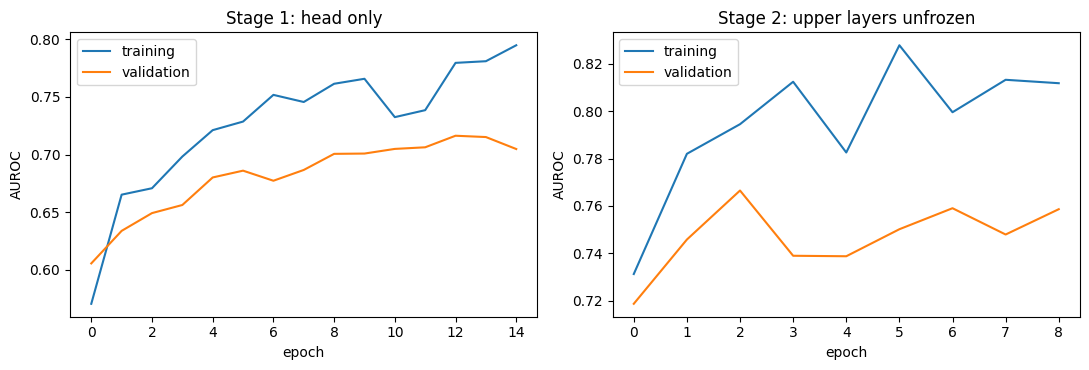

In [6]:
set_seed(CFG["seed"])
model = build_model()

rot = keras.layers.RandomRotation(0.03, fill_mode="reflect", seed=CFG["seed"])
def augment(x, y):                           # flips, small rotation, small contrast and brightness changes
    x = tf.image.random_flip_left_right(x); x = tf.image.random_flip_up_down(x)
    x = rot(x, training=True)
    x = tf.image.random_contrast(x, 0.85, 1.15) + tf.random.uniform([], -15.0, 15.0)
    return tf.clip_by_value(x, 0.0, 255.0), y

ds_tr = (tf.data.Dataset.from_tensor_slices((rgb(X_tr), y_tr.astype("float32")))
         .shuffle(len(y_tr), seed=CFG["seed"], reshuffle_each_iteration=True)
         .batch(CFG["batch"]).map(augment, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE))
ds_va = tf.data.Dataset.from_tensor_slices((rgb(X_va), y_va.astype("float32"))).batch(64)
n1 = int(y_tr.sum()); n0 = len(y_tr) - n1
class_weight = {0: len(y_tr) / (2 * n0), 1: len(y_tr) / (2 * n1)}
print("Class weights:", {k: round(v, 3) for k, v in class_weight.items()})

def fit_stage(lr, epochs, unfreeze_from):
    set_trainable(model, unfreeze_from)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss=keras.losses.BinaryCrossentropy(from_logits=True),
                  metrics=[keras.metrics.AUC(from_logits=True, name="auc")])
    stop = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=CFG["patience"], restore_best_weights=True)
    h = model.fit(ds_tr, validation_data=ds_va, epochs=epochs, class_weight=class_weight, callbacks=[stop], verbose=2)
    return roc_auc_score(y_va, scores(model, X_va)), h.history

W = os.path.join(OUT, "best.weights.h5")
auc1, h1 = fit_stage(CFG["lr_head"], CFG["epochs_head"], None)
model.save_weights(W); print(f"\nStage 1 (head only) validation AUROC: {auc1:.3f}\n")
auc2, h2 = fit_stage(CFG["lr_ft"], CFG["epochs_ft"], CFG["unfreeze_from"])
print(f"\nStage 2 (upper layers unfrozen) validation AUROC: {auc2:.3f}")
if auc2 >= auc1:
    model.save_weights(W); kept = "stage 2"
else:
    model.load_weights(W); kept = "stage 1"
print("Keeping", kept)
model.save(os.path.join(OUT, "model.keras"))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for k, (h, name) in enumerate(((h1, "Stage 1: head only"), (h2, "Stage 2: upper layers unfrozen"))):
    ax[k].plot(h["auc"], label="training"); ax[k].plot(h["val_auc"], label="validation")
    ax[k].set_title(name); ax[k].set_xlabel("epoch"); ax[k].set_ylabel("AUROC"); ax[k].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT, "training_curves.png"), dpi=130); plt.show()

**Result:**
- Stage 1 ran all 15 epochs; best validation AUROC **0.716** (epoch 13). It was still improving slowly.
- Stage 2 peaked at epoch 3 with validation AUROC **0.767** and stopped after epoch 9. Stage 2 is kept.
- Training AUROC stays above validation in both stages, which suggests some overfitting. (Training AUROC is
  measured on augmented images with dropout on, so the two lines are not measured in exactly the same way.)
- Because the best epoch was chosen by its validation score, 0.767 is slightly optimistic. Notebook 04 gives
  the number to report.

## 6. Calibration and threshold (validation only), then lock
- **Temperature scaling:** one number *T*. Probability = sigmoid(score / *T*). *T* is chosen to minimise log
  loss on validation. *T* > 1 makes probabilities less extreme; *T* < 1 more extreme. It changes the
  probabilities, never the ranking, so AUROC is unchanged.
- **Threshold:** the highest probability that still flags at least 90% of malignant validation masses.
- **ECE (expected calibration error):** patches are grouped by probability; ECE is the average gap between the
  probability shown and the share actually malignant. 0 = perfectly calibrated.

In [7]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))
def nll(z, y, T):
    p = np.clip(sigmoid(z / T), 1e-7, 1 - 1e-7); return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
def ece(y, p, bins=10):
    e = 0.0
    for b in range(bins):
        lo, hi = b / bins, (b + 1) / bins
        m = (p >= lo) & ((p < hi) if b < bins - 1 else (p <= hi))
        if m.any(): e += m.mean() * abs(y[m].mean() - p[m].mean())
    return e

z_va = scores(model, X_va)
T = float(minimize_scalar(lambda t: nll(z_va, y_va, t), bounds=(0.05, 20), method="bounded").x)
p_va = sigmoid(z_va / T)
ok = [t for t in np.unique(p_va) if (p_va[y_va == 1] >= t).mean() >= CFG["target_sensitivity"]]
THR = float(max(ok)) if ok else 0.5
pred = p_va >= THR

LOCK = dict(temperature=T, threshold=THR, target_sensitivity=CFG["target_sensitivity"], kept=kept,
            val_auroc_finetuned=float(roc_auc_score(y_va, z_va)),
            val_auroc_baseline=float(roc_auc_score(y_va, p_base_va)),
            val_auroc_stage1=float(auc1), val_auroc_stage2=float(auc2),
            val_sensitivity=float(pred[y_va == 1].mean()), val_specificity=float((~pred[y_va == 0]).mean()),
            val_ece_before=float(ece(y_va, sigmoid(z_va))), val_ece_after=float(ece(y_va, p_va)),
            config=CFG, tensorflow=tf.__version__)
json.dump(LOCK, open(os.path.join(OUT, "locked.json"), "w"), indent=2)
pd.DataFrame({"roi_id": d_va.roi_id, "patient_id": d_va.patient_id, "label": y_va, "score": z_va,
              "p_finetuned": p_va, "p_baseline": p_base_va}).to_csv(os.path.join(OUT, "val_predictions.csv"), index=False)

print(f"""
LOCKED (do not change these after looking at test results)
  temperature              {T:.3f}
  threshold                {THR:.3f}
Validation results
  baseline AUROC           {LOCK['val_auroc_baseline']:.3f}
  fine-tuned AUROC         {LOCK['val_auroc_finetuned']:.3f}   ({kept})
  sensitivity at threshold {LOCK['val_sensitivity']:.3f}
  specificity at threshold {LOCK['val_specificity']:.3f}
  calibration error        {LOCK['val_ece_before']:.3f} before scaling -> {LOCK['val_ece_after']:.3f} after
""")
print("Files:", sorted(os.listdir(OUT)))


LOCKED (do not change these after looking at test results)
  temperature              1.208
  threshold                0.279
Validation results
  baseline AUROC           0.733
  fine-tuned AUROC         0.767   (stage 2)
  sensitivity at threshold 0.905
  specificity at threshold 0.359
  calibration error        0.098 before scaling -> 0.110 after

Files: ['baseline_logreg.joblib', 'best.weights.h5', 'locked.json', 'model.keras', 'training_curves.png', 'val_predictions.csv']


**Result (validation)**

| Measure | Value |
|---|---|
| Baseline AUROC | 0.733 |
| Fine-tuned AUROC (stage 2) | 0.767 |
| Temperature | 1.208 |
| Threshold | 0.279 |
| Sensitivity at threshold | 0.905 |
| Specificity at threshold | 0.359 |
| Calibration error, before → after scaling | 0.098 → 0.110 |

**Reading these numbers**
- Fine-tuning added +0.034 AUROC over the baseline on validation. With 197 patches this gap may be partly chance;
  notebook 04 tests it with a confidence interval.
- To catch 90% of malignant masses, the model flags about two-thirds of benign masses as well.
- The temperature is close to 1, so the model was already roughly calibrated; scaling made no meaningful
  difference (a change of 0.01 in ECE is within noise with about 20 patches per group). The temperature is kept,
  as planned.

**These are validation numbers, used for choosing settings, not for reporting.**
**Next:** notebook 04 attaches this notebook's output and notebook 02's, and tests the locked models.